In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import glob
import re
import os

sns.set_theme(style="darkgrid")
palette = {"Baseline": "blue", "Test": "red"}

def get_agent_type(match_num, player_id):
    """Maps the player ID to the agent type based on your 4-match cycle."""
    mod = match_num % 4
    if mod == 1:   # 1v1: [Baseline, Test]
        return "Baseline" if player_id == 0 else "Test"
    elif mod == 2: # 1v1: [Test, Baseline]
        return "Test" if player_id == 0 else "Baseline"
    elif mod == 3: # 4v4: [Baseline, Test, Baseline, Test]
        return "Baseline" if player_id in [0, 2] else "Test"
    elif mod == 0: # 4v4: [Test, Baseline, Test, Baseline]
        return "Test" if player_id in [0, 2] else "Baseline"
    return "Unknown"

def load_replay(filepath):
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            html_content = f.read()
        raw_tail = html_content.split('window.kaggle = ', 1)[1]
        json_string_candidate = raw_tail.split('window.kaggle.renderer', 1)[0]
        return json.loads(json_string_candidate.strip().rstrip(';'))['environment']['steps']
    except Exception as e:
        print(f"Failed to parse {filepath}: {e}")
        return None

# FIND ALL REPLAYS - Adjust the path to your directory
# Assuming files are named like "match_1_...", "match_2_...", etc.
replay_files = glob.glob("/home/saksham/Documents/kaggle/OrbitWars/replays/match_*.html")
print(f"Found {len(replay_files)} replays to process.")

Found 100 replays to process.


In [2]:
master_economy = []
master_launches = []
match_outcomes = []

for filepath in replay_files:
    # This regex looks for "match_X_YvY" and captures X and YvY
    match_search = re.search(r'match_(\d+)_(\dv\d)', filepath)
    if not match_search:
        print(f"Skipping badly named file: {filepath}")
        continue
    
    match_num = int(match_search.group(1))
    mode = match_search.group(2) # Directly grabs "1v1" or "4v4" from the filename!
    
    steps = load_replay(filepath)
    if not steps:
        continue
        
    seen_fleets = set()
    
    # Fast-forward to the last step to get final scores
    final_obs = steps[-1][0]['observation']
    final_planets = final_obs['planets']
    final_fleets = final_obs.get('fleets', [])
    
    scores = {0:0, 1:0, 2:0, 3:0}
    for p in final_planets:
        if p[1] != -1: scores[p[1]] += p[5]
    for f in final_fleets:
        scores[f[1]] += f[6]
        
    # Determine winner(s)
    for p_id in range(4 if mode == "4v4" else 2):
        agent_type = get_agent_type(match_num, p_id)
        match_outcomes.append({
            'Match': match_num,
            'Mode': mode,
            'Agent': agent_type,
            'Score': scores[p_id]
        })

    # Time-series extraction
    for turn_idx, step in enumerate(steps):
        obs = step[0]['observation']
        planets = obs['planets']
        fleets = obs.get('fleets', [])
        
        turn_data = {"Baseline": {"Planets": 0, "Fleets": 0, "Prod": 0},
                     "Test":     {"Planets": 0, "Fleets": 0, "Prod": 0}}
        
        for p in planets:
            owner = p[1]
            if owner != -1:
                atype = get_agent_type(match_num, owner)
                turn_data[atype]["Planets"] += p[5]
                turn_data[atype]["Prod"] += p[6]
                
        for f in fleets:
            owner = f[1]
            atype = get_agent_type(match_num, owner)
            turn_data[atype]["Fleets"] += f[6]
            
            if f[0] not in seen_fleets:
                seen_fleets.add(f[0])
                master_launches.append({
                    'Match': match_num, 'Turn': turn_idx, 
                    'Agent': atype, 'Ships': f[6]
                })
                
        for atype in ["Baseline", "Test"]:
            total = turn_data[atype]["Planets"] + turn_data[atype]["Fleets"]
            if total > 0: # Only record if they are alive
                master_economy.append({
                    'Match': match_num, 'Turn': turn_idx, 'Agent': atype,
                    'Total_Ships': total,
                    'Transit_Pct': (turn_data[atype]["Fleets"] / total) * 100,
                    'Production': turn_data[atype]["Prod"]
                })

df_eco = pd.DataFrame(master_economy)
df_launches = pd.DataFrame(master_launches)
df_outcomes = pd.DataFrame(match_outcomes)
print("Data extraction complete!")

Data extraction complete!


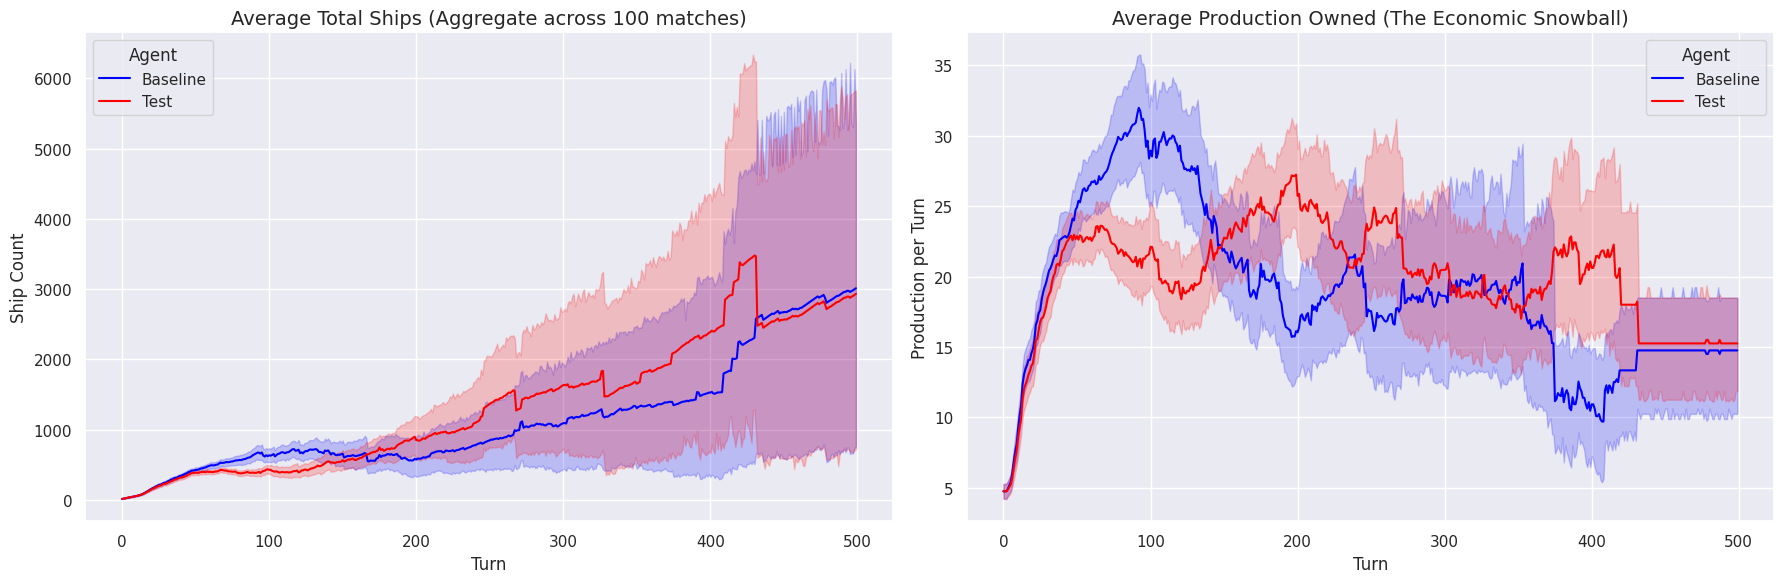

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Subplot 1: Total Ships
sns.lineplot(data=df_eco, x='Turn', y='Total_Ships', hue='Agent', palette=palette, ax=axes[0])
axes[0].set_title('Average Total Ships (Aggregate across 100 matches)', fontsize=14)
axes[0].set_ylabel('Ship Count')

# Subplot 2: Total Production
sns.lineplot(data=df_eco, x='Turn', y='Production', hue='Agent', palette=palette, ax=axes[1])
axes[1].set_title('Average Production Owned (The Economic Snowball)', fontsize=14)
axes[1].set_ylabel('Production per Turn')

plt.tight_layout()
plt.show()

/tmp/ipykernel_7519/40880845.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_launches, x='Agent', y='Ships', palette=palette, showfliers=False)


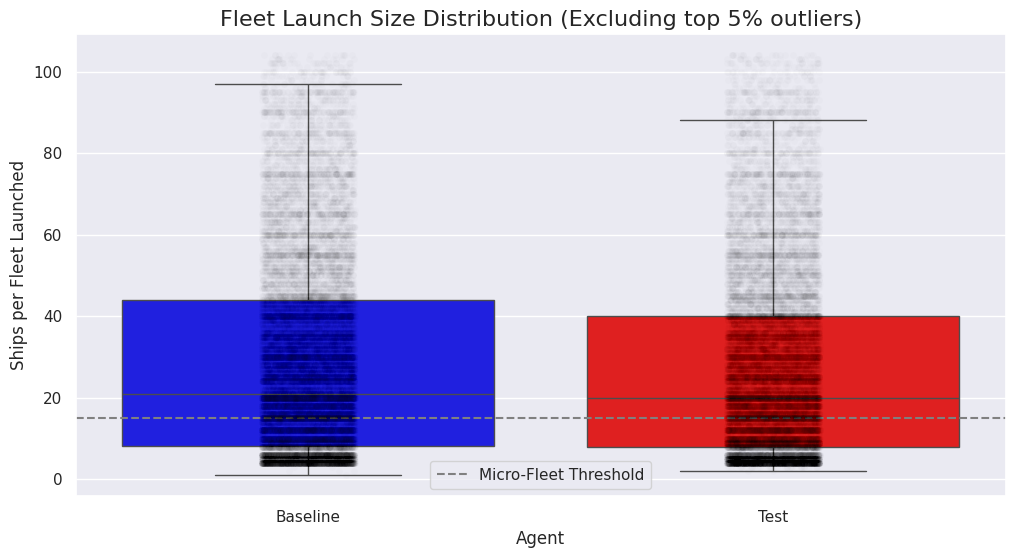

In [4]:
plt.figure(figsize=(12, 6))

# Filter out massive outliers just for readability of the boxplot (e.g. 500+ ship drops)
plot_launches = df_launches[df_launches['Ships'] < df_launches['Ships'].quantile(0.95)]

sns.boxplot(data=plot_launches, x='Agent', y='Ships', palette=palette, showfliers=False)
sns.stripplot(data=plot_launches, x='Agent', y='Ships', color='black', alpha=0.01, jitter=True)

plt.axhline(y=15, color='gray', linestyle='--', label='Micro-Fleet Threshold')
plt.title('Fleet Launch Size Distribution (Excluding top 5% outliers)', fontsize=16)
plt.ylabel('Ships per Fleet Launched')
plt.legend()
plt.show()

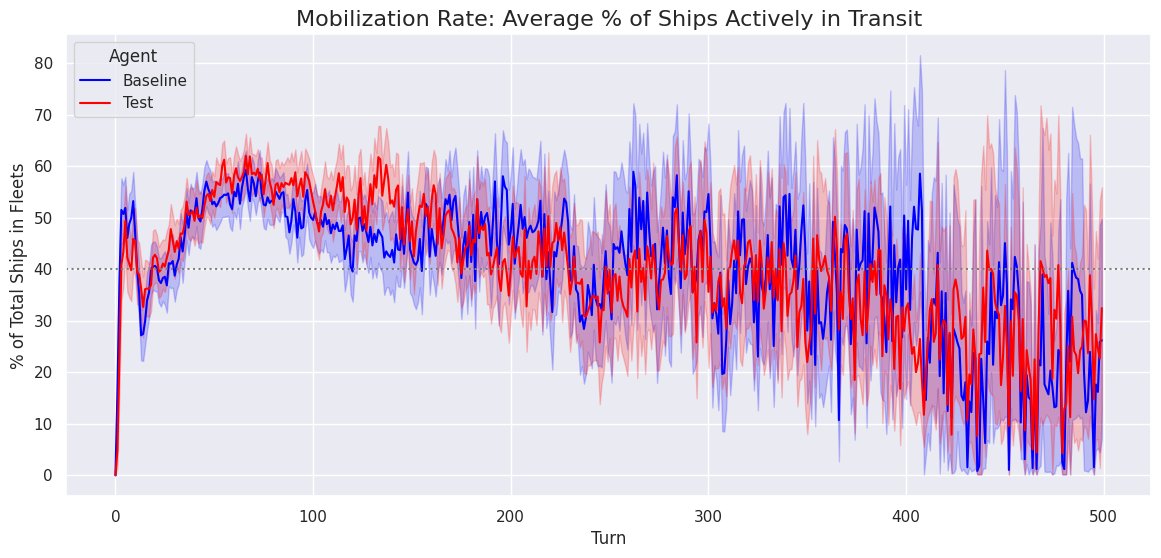

In [5]:
plt.figure(figsize=(14, 6))

# Use rolling average to smooth out the massive turn-by-turn spikes across 100 games
sns.lineplot(data=df_eco, x='Turn', y='Transit_Pct', hue='Agent', palette=palette)

plt.axhline(y=40, color='gray', linestyle=':')
plt.title('Mobilization Rate: Average % of Ships Actively in Transit', fontsize=16)
plt.ylabel('% of Total Ships in Fleets')
plt.show()

In [6]:
# Calculate Average Final Scores
summary = df_outcomes.groupby(['Mode', 'Agent'])['Score'].mean().reset_index()
summary.rename(columns={'Score': 'Average Final Score'}, inplace=True)

# Determine Win Rate (Agent with highest score per match)
idx_winners = df_outcomes.groupby('Match')['Score'].idxmax()
winners = df_outcomes.loc[idx_winners]

win_counts = winners.groupby(['Mode', 'Agent']).size().reset_index(name='Wins')

# Merge and Display
perf_report = pd.merge(summary, win_counts, on=['Mode', 'Agent'], how='left').fillna(0)
perf_report['Wins'] = perf_report['Wins'].astype(int)

print("=== PERFORMANCE REPORT (100 MATCHES) ===")
print(perf_report.to_string(index=False))

=== PERFORMANCE REPORT (100 MATCHES) ===
Mode    Agent  Average Final Score  Wins
 1v1 Baseline              1386.48    43
 1v1     Test               179.74     7
 4v4 Baseline               552.05    19
 4v4     Test               831.40    31
